# Tuberculosis Detection from Chest X-rays Using a Convolutional Neural Network

A deep learning project exploring whether a convolutional neural network (CNN) can classify chest X-ray images as Normal or Tuberculosis (TB). Beyond measuring overall accuracy, this project investigates class-specific performance, examines misclassified images, and considers the implications of model errors in a clinical context.

This project was motivated by my clinical internship in Nigeria, where I encountered many cases of tuberculosis and observed the challenges healthcare systems can face in accessing specialist radiology expertise. This experience motivated me to explore how machine learning might contribute to medical imaging and clinical decision support.

**Dataset:** Tuberculosis (TB) Chest X-ray Database, containing 4,200 images: 3,500 Normal and 700 Tuberculosis images. The dataset was compiled by researchers from Qatar University, the University of Dhaka, Hamad Medical Corporation, and collaborators.

**Note on the dataset version:** The dataset README describes a full release of 3,500 TB images, but 2,800 of them come from the NIAID TB Portals program and require a data-sharing agreement. The version used here contains 700 TB images, consistent with the publicly available portion (306 from the Belarus TB portal and 394 from U.S. National Library of Medicine collections), plus 3,500 Normal images (3,094 from the RSNA Pneumonia Detection Challenge and 406 from NLM collections).

**Technologies:** Python, TensorFlow, Keras, NumPy, Matplotlib, scikit-learn, and Google Colab.

**Hardware:** T4 GPU runtime in Google Colab.

**Important disclaimer:** This is an educational machine-learning project, not a clinically validated diagnostic system. Its predictions should not be used to diagnose or exclude tuberculosis in patients.

**Dataset citation:** Tawsifur Rahman, Amith Khandakar, Muhammad A. Kadir, Khandaker R. Islam, Khandaker F. Islam, Zaid B. Mahbub, Mohamed Arselene Ayari, Muhammad E. H. Chowdhury (2020). "Reliable Tuberculosis Detection using Chest X-ray with Deep Learning, Segmentation and Visualization." *IEEE Access*, Vol. 8, pp. 191586-191601. DOI: 10.1109/ACCESS.2020.3031384.

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'archive.zip', 'sample_data']


In [ ]:
import zipfile

with zipfile.ZipFile('/content/archive.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/tb_data')

In [ ]:
import os
os.listdir('/content/tb_data')

['TB_Chest_Radiography_Database']

In [ ]:
os.listdir('/content/tb_data/TB_Chest_Radiography_Database')

['Normal.metadata.xlsx',
 'README.md.txt',
 'Tuberculosis',
 'Tuberculosis.metadata.xlsx',
 'Normal']

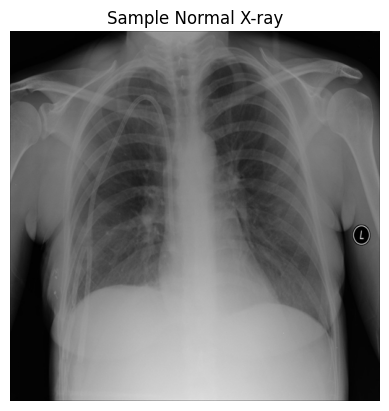

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/tb_data/TB_Chest_Radiography_Database/Normal/Normal-1.png')
plt.imshow(img, cmap='gray')
plt.title('Sample Normal X-ray')
plt.axis('off')
plt.show()

In [ ]:
normal_count = len(os.listdir('/content/tb_data/TB_Chest_Radiography_Database/Normal'))
tb_count = len(os.listdir('/content/tb_data/TB_Chest_Radiography_Database/Tuberculosis'))

print(f"Normal images: {normal_count}")
print(f"TB images: {tb_count}")

Normal images: 3500
TB images: 700


## Class Distribution

The dataset contains 3,500 Normal images and 700 Tuberculosis images, meaning that Normal images outnumber TB images by a ratio of 5:1.

This class imbalance matters because a model can achieve deceptively high accuracy by favoring the majority class. For example, a classifier that predicts every image as Normal would achieve approximately 83.3% accuracy across the full dataset while failing to identify any TB cases.

For a screening-oriented task, this would be an unacceptable outcome despite the apparently high accuracy.

For this reason, I evaluated the model using a confusion matrix, precision, recall, and F1-score in addition to overall accuracy. Particular attention was given to recall for the TB class, which measures the proportion of TB-positive images correctly identified by the model.

The objective was not simply to maximize accuracy, but to assess whether the model could identify TB-positive images while also recognizing the limitations of its predictions.

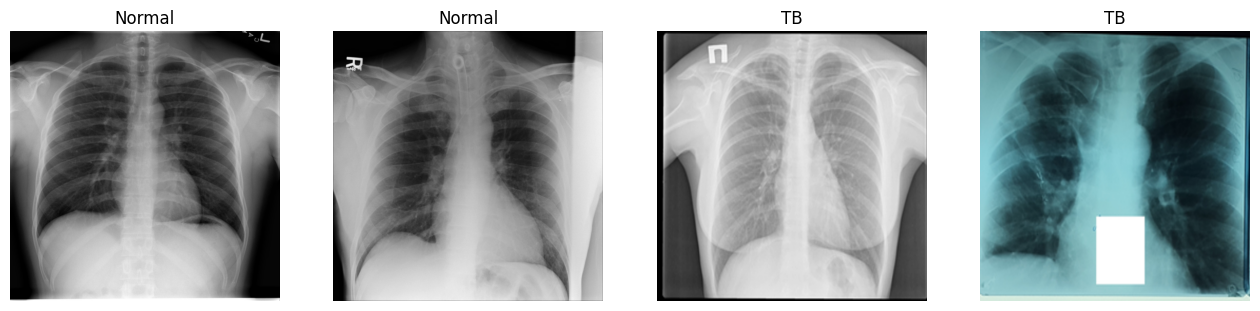

In [ ]:
tb_files = os.listdir('/content/tb_data/TB_Chest_Radiography_Database/Tuberculosis')
normal_files = os.listdir('/content/tb_data/TB_Chest_Radiography_Database/Normal')

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for i in range(2):
    img = mpimg.imread(f'/content/tb_data/TB_Chest_Radiography_Database/Normal/{normal_files[i]}')
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title('Normal')
    axes[i].axis('off')

for i in range(2):
    img = mpimg.imread(f'/content/tb_data/TB_Chest_Radiography_Database/Tuberculosis/{tb_files[i]}')
    axes[i+2].imshow(img, cmap='gray')
    axes[i+2].set_title('TB')
    axes[i+2].axis('off')

plt.show()

## Loading and Inspecting the Data

The dataset contains chest X-ray images organized into two classes: Normal and Tuberculosis. Before training the model, I loaded and displayed representative images from both classes to confirm that the data had been imported correctly and to examine the images visually.

My medical background allowed me to approach the images with some clinical context. However, as a physician without specialist radiology training, I could not confidently identify or explain every radiological finding, particularly when abnormalities were subtle or nonspecific.

This highlighted an important aspect of the project: interpreting medical images requires specialist expertise, and machine-learning models must be evaluated carefully before their predictions can be considered useful in clinical practice. Imaging-based decision-support tools may have potential to assist healthcare professionals, particularly in settings where access to specialist expertise is limited, but their usefulness depends on rigorous validation.

In [ ]:
import tensorflow as tf

img_size = (224, 224)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/tb_data/TB_Chest_Radiography_Database',
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/tb_data/TB_Chest_Radiography_Database',
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

Found 4200 files belonging to 2 classes.
Using 3360 files for training.
Found 4200 files belonging to 2 classes.
Using 840 files for validation.


## Preparing the Images

The images (originally 512 × 512 pixels) were resized to 224 × 224 pixels to provide the model with uniform input dimensions. Pixel intensities were rescaled from the original 0–255 range to values between 0 and 1, helping to standardize the numerical inputs during training.

The dataset was divided into training and validation subsets using an 80/20 split:

- **Training set:** 3,360 images.
- **Validation set:** 840 images.

Images were loaded in batches of 32 to manage memory use during training.

The training set was used to optimize the model's parameters, while the validation set was used to monitor performance during training and assess the model at the end of the experiment.

Because the dataset did not provide patient identifiers for splitting, the division was performed at the image level rather than the patient level. If multiple images from the same patient were present, images from that patient could potentially appear in both subsets. This is an important limitation when interpreting the validation results.

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,825,345 (10.78 MB)

 Trainable params: 2,825,345 (10.78 MB)

 Non-trainable params: 0 (0.00 B)

## Model Architecture

I built a convolutional neural network (CNN) from scratch rather than using a pre-trained image-classification model. This approach allowed me to understand the role of the individual layers and the process of learning visual features directly from the dataset.

The architecture consists of three convolutional and max-pooling blocks, with 32, 64, and 64 filters, respectively. These layers extract increasingly complex spatial features from the images while the pooling operations reduce their spatial dimensions.

The resulting feature maps are flattened and passed through a fully connected layer containing 64 units. A final output layer with a single neuron and sigmoid activation produces a probability-like score for the TB class.

The model contains approximately 2.8 million trainable parameters.

A sigmoid output allows the model's prediction to be interpreted as a score between 0 and 1. Using the classification threshold applied during evaluation, this score is converted into a Normal or TB prediction.

I chose a relatively simple architecture to establish a baseline and develop a practical understanding of CNN-based image classification before considering more advanced approaches such as transfer learning.

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 32s 213ms/step - accuracy: 0.8884 - loss: 0.2665 - val_accuracy: 0.9464 - val_loss: 0.1409
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 33s 214ms/step - accuracy: 0.9568 - loss: 0.1147 - val_accuracy: 0.9702 - val_loss: 0.0833
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 28s 262ms/step - accuracy: 0.9679 - loss: 0.0930 - val_accuracy: 0.9702 - val_loss: 0.0846
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 27s 262ms/step - accuracy: 0.9625 - loss: 0.0984 - val_accuracy: 0.9726 - val_loss: 0.0817
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 222ms/step - accuracy: 0.9628 - loss: 0.0965 - val_accuracy: 0.9738 - val_loss: 0.0846
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 22s 213ms/step - accuracy: 0.9729 - loss: 0.0659 - val_accuracy: 0.9750 - val_loss: 0.0695
Epoch 7/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 21s 201ms/step - accuracy: 0.9851 - loss: 0.0414 - val_accuracy: 0.9833 - val_loss: 0.0538
Epoch 8/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 216ms/step - accuracy: 0.9932 - loss: 0

## Training

The model was compiled using the Adam optimizer and binary cross-entropy loss, then trained for 10 epochs using a T4 GPU runtime in Google Colab.

Training accuracy increased over the course of training, reaching approximately 99.4% by the final epoch. Validation accuracy improved from approximately 94.6% in the first epoch to 98.6% by the end of training.

The small difference between training and validation accuracy is encouraging, although it does not establish that overfitting is absent. Validation loss increased slightly during the final epoch, and the validation set was used to monitor training as well as report the final performance.

Consequently, the results should be interpreted as validation performance rather than as an unbiased estimate of performance on completely independent data.

For context, a classifier that predicted Normal for every image would achieve approximately 83.3% accuracy across the complete dataset. The model's substantially higher validation accuracy suggests that it learned patterns associated with the two classes in this dataset. However, class-specific metrics and further testing are necessary to assess whether those patterns support reliable TB detection beyond this particular collection of images.

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=['Normal', 'Tuberculosis']))

[[697   4]
 [  8 131]]
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       701
Tuberculosis       0.97      0.94      0.96       139

    accuracy                           0.99       840
   macro avg       0.98      0.97      0.97       840
weighted avg       0.99      0.99      0.99       840



## Evaluation Beyond Accuracy

The model achieved approximately 98.6% validation accuracy. However, overall accuracy alone does not reveal how effectively it identified TB-positive images.

The confusion matrix showed the following results:

- **697 Normal images** were correctly classified as Normal.
- **4 Normal images** were incorrectly classified as TB.
- **131 TB images** were correctly classified as TB.
- **8 TB images** were incorrectly classified as Normal.

For the TB class, these results correspond to approximately:

- **Recall (sensitivity): 94.2%.** The model detected 131 of the 139 TB-positive validation images.
- **Precision: 97.0%.** Of the 135 images predicted as TB, 131 were actually labeled TB in the dataset.
- **F1-score: approximately 95.6%.** This summarizes the balance between precision and recall.

The model therefore detected most TB-positive images in the validation set, but it still missed eight cases.

**Run-to-run variation.** After finishing the analysis, I ran the full notebook a second time with identical code, only to confirm that everything worked. The results were not identical:

| | Run 1 (reported above) | Run 2 (identical code) |
|---|---|---|
| Validation accuracy | 98.6% | 97.6% |
| TB images missed | 8 | 6 |
| False alarms (Normal predicted as TB) | 4 | 14 |
| TB recall | 94.2% | 95.7% |
| TB precision | 97.0% | 90.5% |

The data split was the same in both runs (the same 840 validation images). The difference comes from random elements of neural-network training, such as initial weights and batch order, which I did not fix with a random seed. I report the first run in detail because the error analysis below was performed on its misclassified images. The second run missed fewer TB images but produced more false alarms, so it is not clearly better or worse. With only 139 TB images in the validation set, a difference of two missed cases is small enough to treat as run-to-run variation. It also means a single training run gives only a rough picture of model performance.

These errors are particularly important in a screening context. A false negative could contribute to delayed further investigation if a model prediction were incorrectly treated as evidence that TB was absent. A false positive, on the other hand, could lead to additional testing and unnecessary concern.

Compared with my diabetes risk-prediction and ECG arrhythmia-classification projects, this experiment reinforced the importance of evaluating the minority class directly rather than relying on overall accuracy.

However, the results do not establish clinical diagnostic performance. The validation labels are the reference used for this experiment, and the model has not been assessed on an independent test set or externally validated on images from other hospitals and patient populations.

In [ ]:
missed_tb = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    pred_labels = (preds > 0.5).astype(int).flatten()

    for i in range(len(labels)):
        true_label = labels[i].numpy()
        pred_label = pred_labels[i]

        if true_label == 1 and pred_label == 0:
            missed_tb.append(images[i].numpy())

print(f"Found {len(missed_tb)} missed TB cases")

Found 8 missed TB cases


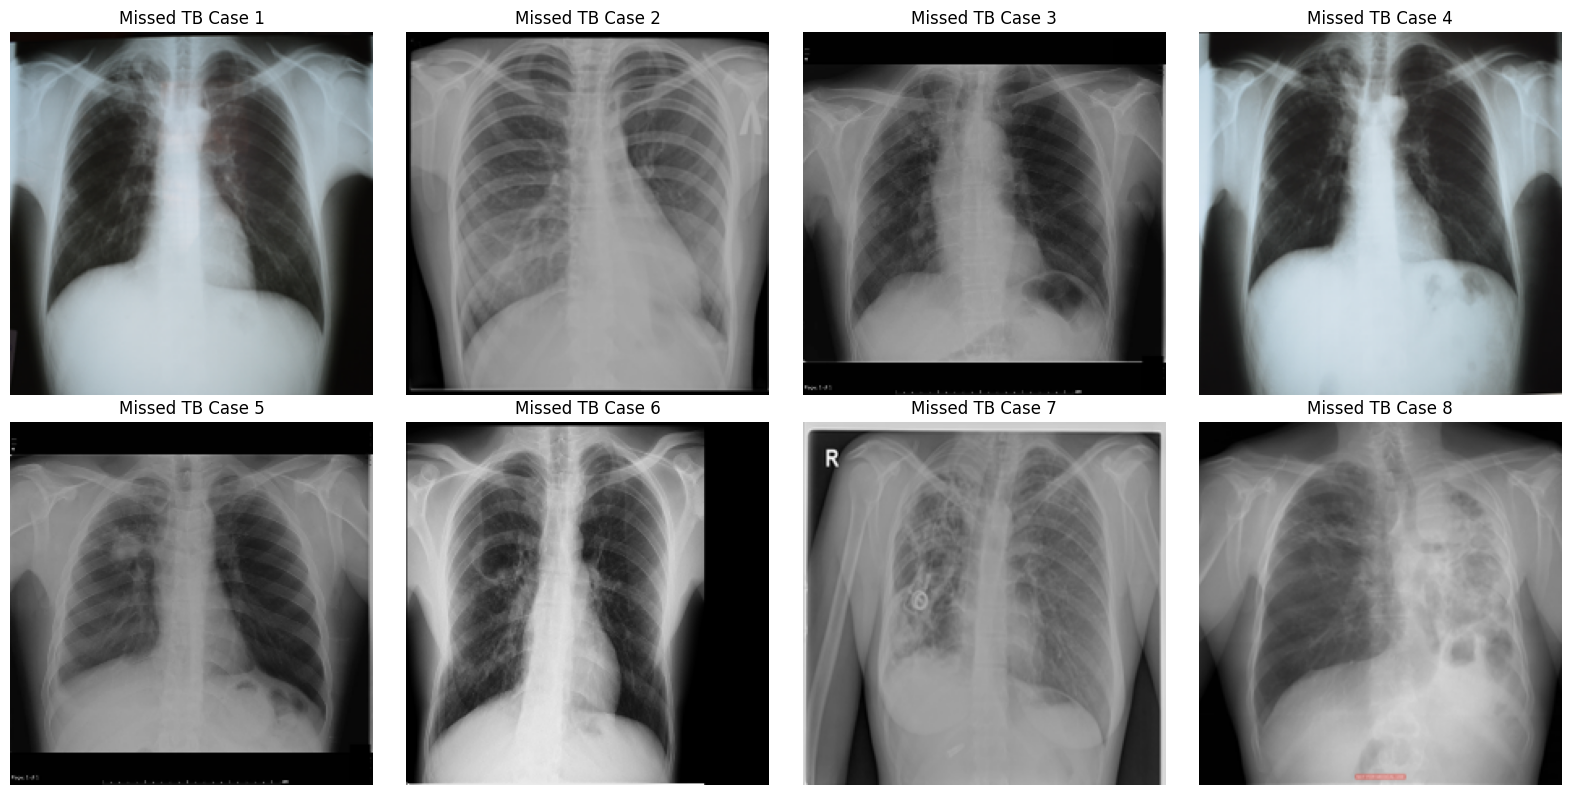

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16,8))
axes = axes.flatten()

for i, img in enumerate(missed_tb):
    axes[i].imshow(img.astype('uint8'))
    axes[i].set_title(f'Missed TB Case {i+1}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## Examining the Missed Cases

I examined the eight TB-positive images that the model incorrectly classified as Normal. This error analysis was particularly interesting because most of the images appeared visibly abnormal to me, even though I could not confidently identify or explain the specific radiological findings.

Approximately two or three images appeared relatively normal on visual inspection, while the remaining images looked markedly abnormal. Some appeared to show extensive consolidation, one had an apparently opaque lung field, and some contained features that looked like medical devices.

These descriptions reflect my informal visual impressions as a physician without specialist radiology training. I cannot independently determine the nature, significance, or cause of the apparent abnormalities, and these observations have not been confirmed by a radiologist. An image that appears abnormal does not necessarily have abnormalities caused by TB, just as an image that appears relatively normal may still contain findings associated with the disease.

The findings raised an important question: why did the model classify several images that appeared markedly abnormal on visual inspection as Normal?

Possible explanations include limitations in the features learned by the model, differences between general radiographic abnormalities and the patterns associated with the TB labels, or other characteristics of the images that influenced its predictions. The presence of medical devices and other visual features also raises questions about whether the model relied on clinically meaningful information. However, I did not investigate these possibilities experimentally, so no causal explanation can be established from these observations alone.

This analysis highlighted an important limitation of aggregate performance metrics: a model can achieve high overall accuracy and still make errors on individual images that appear to warrant further clinical attention.

Further investigation involving specialist radiology review and explainability techniques, such as Gradient-weighted Class Activation Mapping (Grad-CAM), could help explore which image regions influenced the predictions. Such methods may provide useful insights, although they cannot independently prove that a model is relying on clinically appropriate features.

Ultimately, this exercise reinforced the importance of examining misclassified cases, acknowledging uncertainty, and maintaining appropriate human oversight when developing machine-learning systems for medical imaging.

## Limitations and Real-World Context

Although the model achieved strong validation results, several limitations prevent these findings from being interpreted as evidence of clinical readiness.

**1. Single dataset**

The experiment used one compiled chest X-ray dataset. The model has not been evaluated on images from independent hospitals, different X-ray machines, or other patient populations. Its performance in Nigerian clinical settings, which motivated this project, remains unknown.

**2. Different source collections for each class**

According to the dataset README, the two classes were assembled from different original collections. Most Normal images come from the RSNA Pneumonia Detection Challenge (3,094 of 3,500), with the rest from NLM collections (406), while the TB images come from the Belarus TB portal (306) and NLM collections (394). Because the TB and Normal images largely came from different sources, the model may partly be learning differences between collections, such as equipment, image processing, or patient population, instead of, or in addition to, signs of tuberculosis. This could inflate the validation results. I did not test for it. A fairer test would use TB and Normal images from the same source.

**3. No independent test set**

The validation set was used to monitor training and to report the final evaluation metrics. Because model development decisions may be influenced by validation performance, these results may be optimistic estimates of generalization. A separate, untouched test set would provide a more rigorous final evaluation.

**4. Image-level splitting**

The dataset did not provide patient identifiers for constructing a patient-level split. Therefore, images were divided at the image level. If multiple images from the same patient were present, related images could have appeared in both training and validation subsets, potentially inflating the reported performance.

**5. Class imbalance**

The dataset contained five times as many Normal images as TB images. Although the model achieved strong TB recall in this validation set, its performance could change under different class distributions or in populations with different disease prevalence.

**6. Limited error analysis**

Only eight TB-positive validation images were misclassified as Normal. Their visual examination generated questions about the model's failures, but the number of cases was too small to establish consistent error patterns or identify their causes. In addition, the observations were not independently reviewed by a radiologist.

**7. No external clinical validation**

The model was developed as a learning exercise. It has not undergone prospective clinical evaluation, external validation, or assessment of its effects on clinical decisions and patient outcomes. It should not be used as a standalone diagnostic or screening tool.

**8. Run-to-run variability**

Two runs of identical code produced different results (see the Evaluation section). I did not fix random seeds or average results over repeated runs, so the reported numbers reflect a single training run and should be treated as approximate.

### Real-World Context

AI-assisted chest X-ray analysis is an established area of research and application in tuberculosis screening. The World Health Organization has issued guidance on the use of computer-aided detection software for interpreting chest X-rays in TB screening and triage, subject to appropriate conditions and evaluation.

Commercial systems, including Qure.ai's qXR, illustrate how this technology is being developed for real-world screening workflows. However, the performance and suitability of such systems depend on their validation, intended use, and deployment context.

These systems should not be considered equivalent to the CNN developed in this project. Commercial tools and clinically deployed systems require substantially more extensive evaluation than this exploratory experiment.

My model is a practical learning exercise that allowed me to explore a clinically relevant problem, evaluate class-specific performance, and investigate individual errors. Its results demonstrate what can be achieved within this dataset, not that it is ready for clinical use.

## Conclusion

In this project, I developed a convolutional neural network from scratch to classify chest X-ray images as Normal or Tuberculosis. Trained on 3,360 images, the model achieved 98.6% validation accuracy and approximately 94.2% recall for the TB class.

Beyond the overall metrics, examining the eight missed TB cases was one of the most valuable parts of the experiment. Most appeared visibly abnormal to me on informal visual inspection, although I could not confidently explain the specific radiological findings. This raised questions about the features the model learned and highlighted the importance of investigating individual errors rather than relying on aggregate metrics alone.

The results must be interpreted in light of the single-dataset design, the different source collections for the two classes, image-level splitting, and absence of an independent test set or external clinical validation. The model is an educational experiment, not a clinically validated diagnostic tool.

Across my three projects—diabetes risk prediction, ECG arrhythmia classification, and TB detection from chest X-rays—a common lesson has emerged: a single accuracy number is never enough when evaluating machine-learning systems for healthcare.

It is equally important to understand which cases the model gets wrong, investigate why those errors occur, assess whether the model generalizes to new patients, and consider the consequences of its predictions.

This project strengthened my understanding of CNNs, model evaluation, and the challenges of applying machine learning to medical problems. It also reinforced my interest in exploring how technical development and clinical understanding can work together to support responsible healthcare innovation.